# 33 MediaPipe landmarks -> 26 REHAB24-6 joints
Three models (c17, c18, combined), Optuna-tuned, tested on held-out subjects.

In [1]:
!pip install -q optuna

## 1. Config

In [2]:
import os, math, copy, random
import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import optuna
from functools import lru_cache
from tqdm.auto import tqdm

GT_DIR  = "/kaggle/input/datasets/almutalem/rehab24-6/REHAB24-6/2d_joints"
LM_DIR  = "/kaggle/input/datasets/almutalem/rehab24-6-raw-video-mediapipe-landmarks/mediapipe_33_landmarks"
OUT_DIR = "/kaggle/working"

EXERCISES = ["Ex1", "Ex2", "Ex3", "Ex4", "Ex5", "Ex6"]
VIEWS = ["c17", "c18"]
MODEL_SETS = {"c17": ["c17"], "c18": ["c18"], "combined": ["c17", "c18"]}

N_VAL_SUBJECTS, N_TEST_SUBJECTS, SEED = 2, 2, 0
N_TRIALS, TRIAL_EPOCHS = 25, 30
FINAL_EPOCHS, PATIENCE = 150, 20
MAX_STEPS_PER_EPOCH = 400

AUG_FLIP, AUG_ROT_DEG, AUG_SCALE, AUG_JITTER = True, 15, 0.15, 0.01

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print("device:", DEVICE)

device: cuda


## 2. Left/right swap tables (used by flip augmentation)

In [3]:
MP_PAIRS = [(1,4),(2,5),(3,6),(7,8),(9,10),(11,12),(13,14),(15,16),(17,18),(19,20),
            (21,22),(23,24),(25,26),(27,28),(29,30),(31,32)]
GT_PAIRS = [(6,11),(7,12),(8,13),(9,14),(10,15),(16,21),(17,22),(18,23),(19,24),(20,25)]

def flip_index(n, pairs):
    idx = list(range(n))
    for a, b in pairs:
        idx[a], idx[b] = b, a
    return torch.tensor(idx, device=DEVICE)

MP_FLIP, GT_FLIP = flip_index(33, MP_PAIRS), flip_index(26, GT_PAIRS)

## 3. Load data

In [4]:
def video_path(e):
    name = (f"{e['subject']}-Camera17-{e['fps']}.mp4" if e["view"] == "c17"
            else f"{e['subject']}-Camera18-{e['fps']}-transposed.mp4")
    return f"{VID_DIR}/{e['ex']}/{name}"

@lru_cache(maxsize=None)
def video_size(path):
    cap = cv2.VideoCapture(path)
    w, h = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    cap.release()
    return w, h

def find_files():
    files = []
    for ex in EXERCISES:
        if not os.path.isdir(f"{LM_DIR}/{ex}"):
            continue
        for f in sorted(os.listdir(f"{LM_DIR}/{ex}")):
            if f.endswith(".npy") and os.path.exists(f"{GT_DIR}/{ex}/{f}"):
                subject, view, fps = f[:-4].split("-")[:3]
                files.append(dict(ex=ex, subject=subject, view=view, fps=fps, name=f))
    return files

def load_pair(e):
    """-> mp (n,33,2) pixels, gt (n,26,2) pixels, length_mismatch flag"""
    mp = np.load(f"{LM_DIR}/{e['ex']}/{e['name']}").astype(np.float32)
    gt = np.load(f"{GT_DIR}/{e['ex']}/{e['name']}").astype(np.float32)
    mp = mp.reshape(len(mp), 33, -1)[..., :2]
    gt = gt.reshape(len(gt), 26, -1)[..., :2]
    if np.nanmax(np.abs(mp)) <= 2.0:                      # normalized 0-1 -> pixels
        w, h = video_size(video_path(e))
        mp = mp * np.array([w, h], np.float32)
    n = min(len(mp), len(gt))
    return mp[:n], gt[:n], len(mp) != len(gt)

_CACHE = {}
def get_dataset(views):
    key = tuple(views)
    if key in _CACHE:
        return _CACHE[key]
    MP, GT, SUB, mismatch = [], [], [], 0
    for e in tqdm([e for e in FILES if e["view"] in views], desc=f"load {views}"):
        mp, gt, mm = load_pair(e)
        mismatch += mm
        ok = np.isfinite(mp).all((1, 2)) & np.isfinite(gt).all((1, 2)) & (np.abs(mp).sum((1, 2)) > 0)
        MP.append(mp[ok]); GT.append(gt[ok]); SUB += [e["subject"]] * int(ok.sum())
    ds = dict(mp=np.concatenate(MP), gt=np.concatenate(GT), subject=np.array(SUB))
    print(f"{views}: {len(ds['mp'])} frames, {len(set(SUB))} subject IDs, {mismatch} files with length mismatch")
    _CACHE[key] = ds
    return ds

def take(ds, subjects):
    m = np.isin(ds["subject"], subjects)
    assert m.any(), f"no frames for {subjects}"
    return dict(mp=torch.tensor(ds["mp"][m], device=DEVICE), gt=torch.tensor(ds["gt"][m], device=DEVICE))

FILES = find_files()
by_view = {v: {e["subject"] for e in FILES if e["view"] == v} for v in VIEWS}
common = sorted(by_view["c17"] & by_view["c18"])           # test/val subjects must exist in both views
random.Random(SEED).shuffle(common)
SPLITS = dict(test=common[:N_TEST_SUBJECTS],
              val=common[N_TEST_SUBJECTS:N_TEST_SUBJECTS + N_VAL_SUBJECTS])
SPLITS["train"] = sorted({e["subject"] for e in FILES} - set(SPLITS["test"]) - set(SPLITS["val"]))
print(len(FILES), "files | test:", SPLITS["test"], "| val:", SPLITS["val"], "| train subjects:", len(SPLITS["train"]))

130 files | test: ['PM_110', 'PM_042'] | val: ['PM_114', 'PM_008'] | train subjects: 61


## Single-frame MediaPipe check
Runs MediaPipe on one frame of one video and prints everything it returns per landmark.
Also prints the frame size (use it for FRAME_SIZE above if your landmark files are normalized).

In [5]:
!pip install -q mediapipe
!wget -q -O pose_landmarker.task https://storage.googleapis.com/mediapipe-models/pose_landmarker/pose_landmarker_full/float16/1/pose_landmarker_full.task

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.


frame size: width=1920, height=1080


INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1792997312.801331     193 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792997312.847741     193 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792997312.901017     194 landmark_projection_calculator.cc:81] Using NORM_RECT without IMAGE_DIMENSIONS is only supported for the square ROI. Provide IMAGE_DIMENSIONS or use PROJECTION_MATRIX.


poses detected: 1
 id         name     x     y      z     x_px     y_px  visibility  presence  world_x  world_y  world_z
  0         nose 0.396 0.225 -0.259  759.806  243.144       1.000     1.000   -0.004   -0.660   -0.258
  1  l_eye_inner 0.399 0.215 -0.241  766.731  232.178       1.000     1.000    0.003   -0.698   -0.240
  2        l_eye 0.402 0.216 -0.241  771.734  232.900       1.000     1.000    0.004   -0.699   -0.239
  3  l_eye_outer 0.405 0.216 -0.241  776.725  233.626       1.000     1.000    0.003   -0.699   -0.239
  4  r_eye_inner 0.391 0.215 -0.242  751.445  231.769       1.000     1.000   -0.029   -0.694   -0.241
  5        r_eye 0.388 0.215 -0.242  745.167  232.126       1.000     1.000   -0.029   -0.695   -0.241
  6  r_eye_outer 0.385 0.215 -0.242  738.339  232.597       1.000     1.000   -0.029   -0.696   -0.240
  7        l_ear 0.407 0.224 -0.129  780.658  242.445       0.999     1.000    0.053   -0.690   -0.129
  8        r_ear 0.376 0.225 -0.138  722.737  242.744  

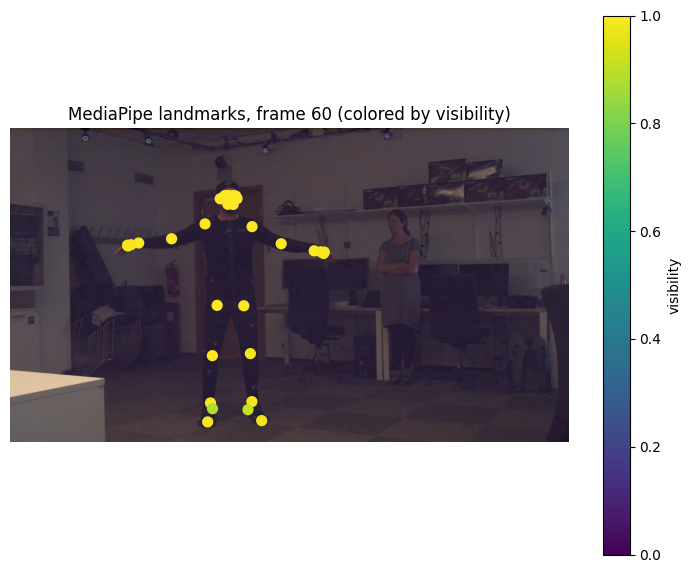

In [6]:
import mediapipe as mp
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision
import cv2
import pandas as pd
import matplotlib.pyplot as plt

VIDEO = "/kaggle/input/datasets/almutalem/raw-rehab24-6-video/Ex1/PM_000-Camera17-30fps.mp4"
FRAME_IDX = 60
NAMES = ["nose", "l_eye_inner", "l_eye", "l_eye_outer", "r_eye_inner", "r_eye", "r_eye_outer",
         "l_ear", "r_ear", "mouth_l", "mouth_r", "l_shoulder", "r_shoulder", "l_elbow", "r_elbow",
         "l_wrist", "r_wrist", "l_pinky", "r_pinky", "l_index", "r_index", "l_thumb", "r_thumb",
         "l_hip", "r_hip", "l_knee", "r_knee", "l_ankle", "r_ankle", "l_heel", "r_heel",
         "l_foot_index", "r_foot_index"]

cap = cv2.VideoCapture(VIDEO); cap.set(cv2.CAP_PROP_POS_FRAMES, FRAME_IDX)
ok, frame = cap.read(); cap.release()
assert ok, "could not read the frame"
h, w = frame.shape[:2]
rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
print(f"frame size: width={w}, height={h}")

detector = vision.PoseLandmarker.create_from_options(vision.PoseLandmarkerOptions(
    base_options=mp_python.BaseOptions(model_asset_path="pose_landmarker.task"),
    num_poses=1, min_pose_detection_confidence=0.5,
    min_pose_presence_confidence=0.5, min_tracking_confidence=0.5))
res = detector.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb))
detector.close()
print("poses detected:", len(res.pose_landmarks))

if res.pose_landmarks:
    val = lambda v: np.nan if v is None else v
    rows = []
    for i, (lm, wl) in enumerate(zip(res.pose_landmarks[0], res.pose_world_landmarks[0])):
        rows.append(dict(id=i, name=NAMES[i], x=lm.x, y=lm.y, z=lm.z, x_px=lm.x * w, y_px=lm.y * h,
                         visibility=val(lm.visibility), presence=val(lm.presence),
                         world_x=wl.x, world_y=wl.y, world_z=wl.z))
    df = pd.DataFrame(rows).round(3)
    print(df.to_string(index=False))
    print("\nlandmarks with visibility < 0.5:", int((df["visibility"] < 0.5).sum()), "of 33")

    plt.figure(figsize=(9, 7))
    plt.imshow(rgb)
    sc = plt.scatter(df["x_px"], df["y_px"], c=df["visibility"], cmap="viridis", vmin=0, vmax=1, s=50)
    plt.colorbar(sc, label="visibility")
    plt.title(f"MediaPipe landmarks, frame {FRAME_IDX} (colored by visibility)")
    plt.axis("off"); plt.show()

Joint letters: {'A': 'Hips', 'B': 'Spine', 'C': 'Spine1', 'D': 'Neck', 'E': 'Head', 'F': 'Head_end', 'G': 'LeftShoulder', 'H': 'LeftArm', 'I': 'LeftForeArm', 'J': 'LeftHand', 'K': 'LeftHand_end', 'L': 'RightShoulder', 'M': 'RightArm', 'N': 'RightForeArm', 'O': 'RightHand', 'P': 'RightHand_end', 'Q': 'LeftUpLeg', 'R': 'LeftLeg', 'S': 'LeftFoot', 'T': 'LeftToeBase', 'U': 'LeftToeBase_end', 'V': 'RightUpLeg', 'W': 'RightLeg', 'X': 'RightFoot', 'Y': 'RightToeBase', 'Z': 'RightToeBase_end'}


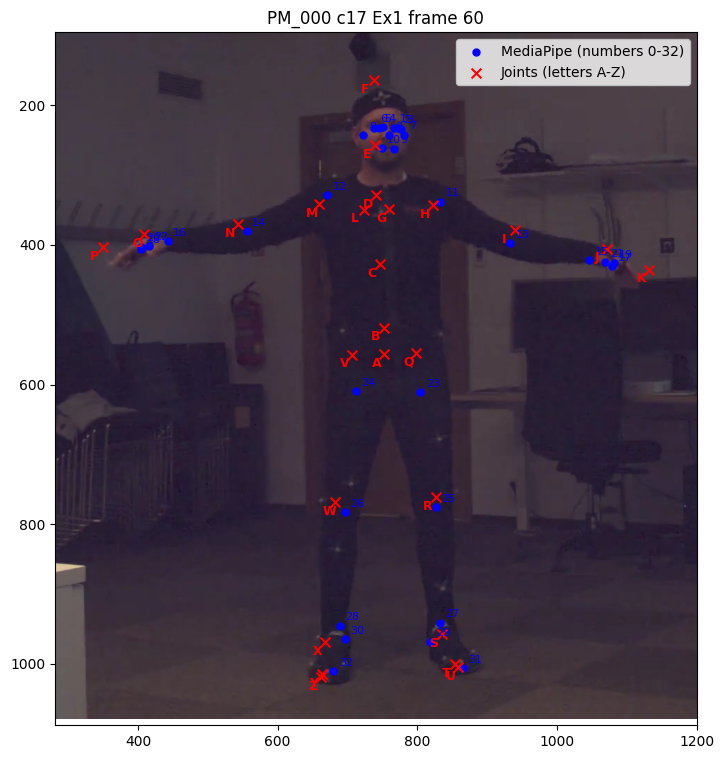

In [7]:
import os, cv2, numpy as np
import matplotlib.pyplot as plt

GT_DIR  = "/kaggle/input/datasets/almutalem/rehab24-6/REHAB24-6/2d_joints"
LM_DIR  = "/kaggle/input/datasets/almutalem/rehab24-6-raw-video-mediapipe-landmarks/mediapipe_33_landmarks"
VID_DIR = "/kaggle/input/datasets/almutalem/raw-rehab24-6-video"

EX, SUBJECT, VIEW, FPS, FRAME = "Ex1", "PM_000", "c17", "30fps", 60

JOINT_NAMES = ["Hips", "Spine", "Spine1", "Neck", "Head", "Head_end",
               "LeftShoulder", "LeftArm", "LeftForeArm", "LeftHand", "LeftHand_end",
               "RightShoulder", "RightArm", "RightForeArm", "RightHand", "RightHand_end",
               "LeftUpLeg", "LeftLeg", "LeftFoot", "LeftToeBase", "LeftToeBase_end",
               "RightUpLeg", "RightLeg", "RightFoot", "RightToeBase", "RightToeBase_end"]
LETTERS = [chr(ord("A") + i) for i in range(26)]          # A..Z, one letter per joint
print("Joint letters:", {l: n for l, n in zip(LETTERS, JOINT_NAMES)})

def load_frame(ex, subject, view, fps, frame):
    name = f"{subject}-{view}-{fps}.npy"
    mp = np.load(f"{LM_DIR}/{ex}/{name}").astype(np.float32)
    gt = np.load(f"{GT_DIR}/{ex}/{name}").astype(np.float32)
    mp = mp.reshape(len(mp), 33, -1)[frame, :, :2]
    gt = gt.reshape(len(gt), 26, -1)[frame, :, :2]

    vid = (f"{VID_DIR}/{ex}/{subject}-Camera17-{fps}.mp4" if view == "c17"
           else f"{VID_DIR}/{ex}/{subject}-Camera18-{fps}-transposed.mp4")
    cap = cv2.VideoCapture(vid); cap.set(cv2.CAP_PROP_POS_FRAMES, frame)
    ok, img = cap.read(); cap.release()
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB) if ok else None

    if np.abs(mp).max() <= 2.0:                           # landmarks are normalized 0-1 -> pixels
        assert img is not None, "landmarks are normalized and the video frame could not be read"
        mp = mp * np.array([img.shape[1], img.shape[0]], np.float32)
    return mp, gt, img

def plot_numbered(mp, gt, img=None, title=""):
    plt.figure(figsize=(11, 9))
    if img is not None:
        plt.imshow(img)
    plt.scatter(mp[:, 0], mp[:, 1], c="blue", s=25, label="MediaPipe (numbers 0-32)")
    plt.scatter(gt[:, 0], gt[:, 1], c="red", marker="x", s=50, label="Joints (letters A-Z)")
    for i, (x, y) in enumerate(mp):
        plt.annotate(str(i), (x, y), xytext=(4, 4), textcoords="offset points", color="blue", fontsize=8)
    for i, (x, y) in enumerate(gt):
        plt.annotate(LETTERS[i], (x, y), xytext=(-9, -9), textcoords="offset points", color="red",
                     fontsize=9, fontweight="bold")
    pts = np.vstack([mp, gt])                              # zoom to the body so the face points are readable
    m = 0.08 * (pts.max(0) - pts.min(0)).max()
    plt.xlim(pts[:, 0].min() - m, pts[:, 0].max() + m)
    plt.ylim(pts[:, 1].max() + m, pts[:, 1].min() - m)
    plt.gca().set_aspect("equal")
    plt.legend(loc="upper right"); plt.title(title); plt.show()

mp, gt, img = load_frame(EX, SUBJECT, VIEW, FPS, FRAME)
plot_numbered(mp, gt, img, f"{SUBJECT} {VIEW} {EX} frame {FRAME}")

## Group mapping v2 (torso can be hidden)
Landmark groups partition the 33 MediaPipe points. Each joint lists the groups that must be
visible for it to be predicted and trained on. The anchor falls back when a torso end is hidden.

OK: 33 landmarks and 26 joints mapped


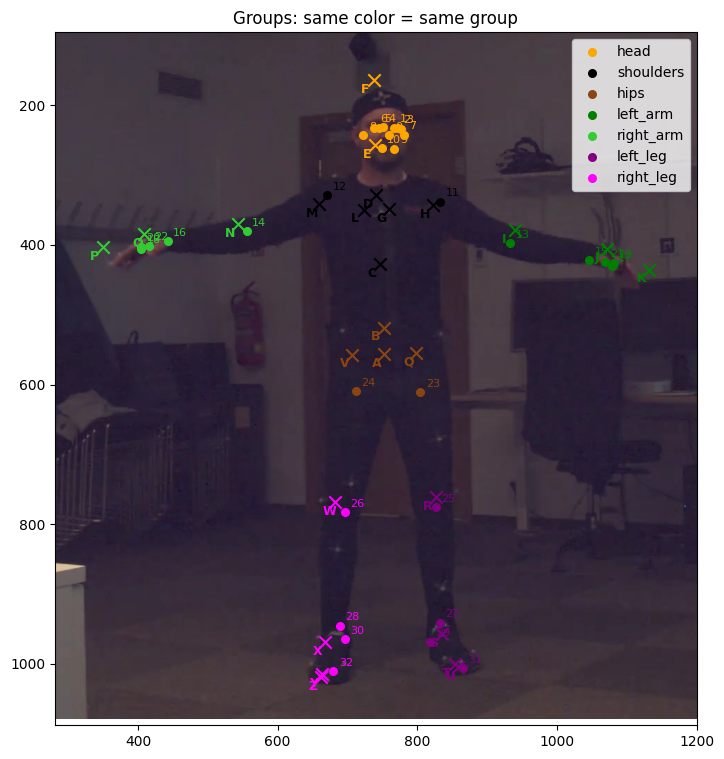

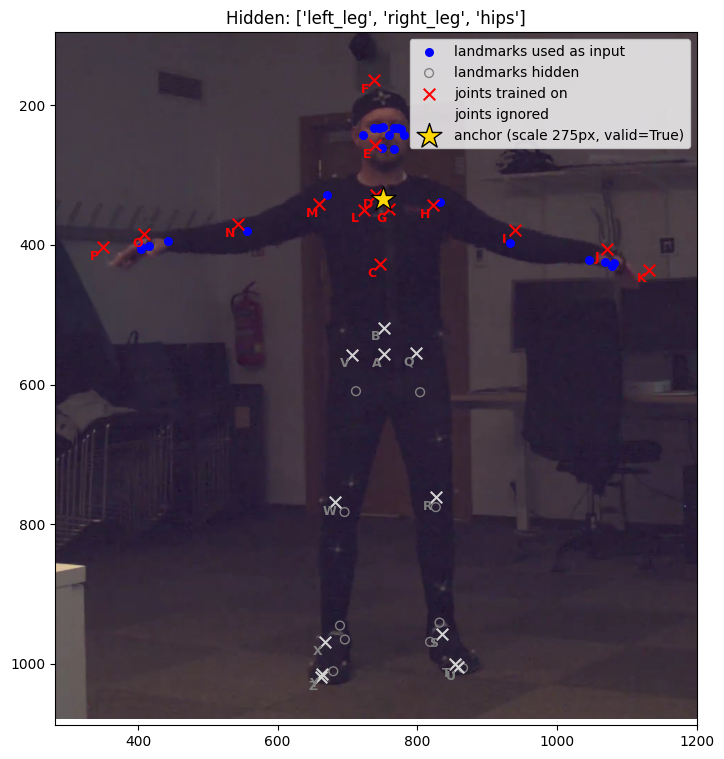

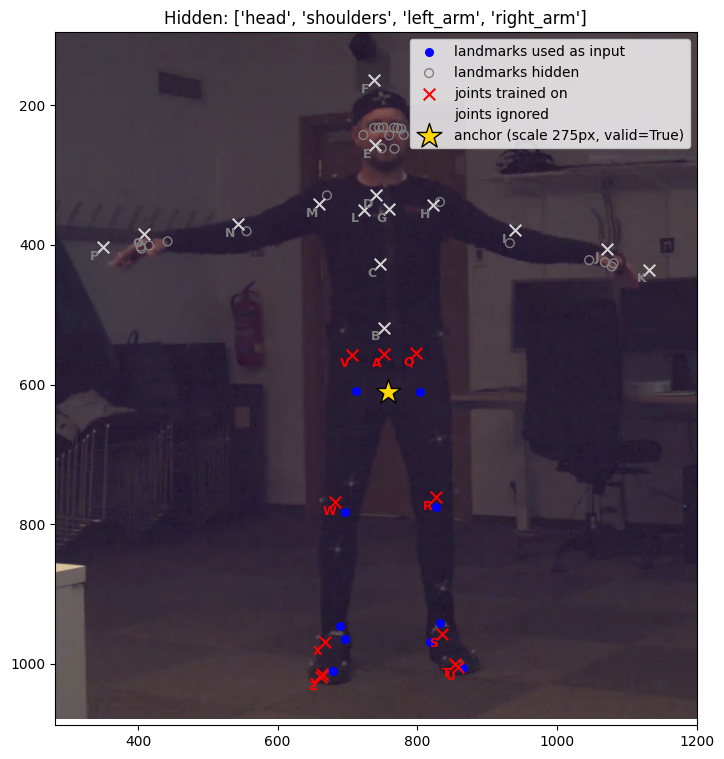

In [8]:
import numpy as np
import torch
import matplotlib.pyplot as plt

LM_GROUPS = {
    "head":      list(range(0, 11)),
    "shoulders": [11, 12],
    "hips":      [23, 24],
    "left_arm":  [13, 15, 17, 19, 21],
    "right_arm": [14, 16, 18, 20, 22],
    "left_leg":  [25, 27, 29, 31],
    "right_leg": [26, 28, 30, 32],
}
GROUP_NAMES = list(LM_GROUPS)
G = len(GROUP_NAMES)

JOINT_NEEDS = {                      # joint index -> groups that must be visible
    0: ["hips"],                                   # A Hips
    1: ["hips", "shoulders"],                      # B Spine
    2: ["shoulders"], 3: ["shoulders"],            # C Spine1, D Neck
    4: ["head"], 5: ["head"],                      # E Head, F Head_end
    6: ["shoulders"], 7: ["shoulders"],            # G LeftShoulder, H LeftArm
    8: ["left_arm"], 9: ["left_arm"], 10: ["left_arm"],          # I, J, K
    11: ["shoulders"], 12: ["shoulders"],          # L RightShoulder, M RightArm
    13: ["right_arm"], 14: ["right_arm"], 15: ["right_arm"],     # N, O, P
    16: ["hips"],                                  # Q LeftUpLeg
    17: ["left_leg"], 18: ["left_leg"], 19: ["left_leg"], 20: ["left_leg"],       # R, S, T, U
    21: ["hips"],                                  # V RightUpLeg
    22: ["right_leg"], 23: ["right_leg"], 24: ["right_leg"], 25: ["right_leg"],   # W, X, Y, Z
}

# --- checks: every landmark in exactly one group, every joint defined, names valid
assert sorted(i for v in LM_GROUPS.values() for i in v) == list(range(33)), "landmark coverage problem"
assert sorted(JOINT_NEEDS) == list(range(26)), "every joint needs an entry"
assert all(g in LM_GROUPS for v in JOINT_NEEDS.values() for g in v), "unknown group name"
print("OK: 33 landmarks and 26 joints mapped")

# --- lookup tables: hidden groups (B,G) -> landmark visibility (B,33) and trainable joints (B,26)
GROUP_TO_LM = torch.zeros(G, 33)
for gi, name in enumerate(GROUP_NAMES):
    GROUP_TO_LM[gi, LM_GROUPS[name]] = 1.0
GROUP_TO_JOINT = torch.zeros(G, 26)
for j, needs in JOINT_NEEDS.items():
    for name in needs:
        GROUP_TO_JOINT[GROUP_NAMES.index(name), j] = 1.0

def masks_from_hidden(hidden):
    """hidden: (B,G) bool. Returns lm_vis (B,33) bool and joint_ok (B,26) bool."""
    h = hidden.float()
    return (h @ GROUP_TO_LM.to(h.device)) == 0, (h @ GROUP_TO_JOINT.to(h.device)) == 0

# --- hiding scenarios (weights are relative, they are normalized below)
SCENARIOS = [
    ([], 0.34),                                              # full body
    (["left_leg", "right_leg"], 0.12),                       # legs out of frame
    (["left_leg", "right_leg", "hips"], 0.15),               # whole lower body out (laptop camera)
    (["left_arm"], 0.05), (["right_arm"], 0.05), (["left_arm", "right_arm"], 0.05),
    (["left_leg"], 0.04), (["right_leg"], 0.04),
    (["head"], 0.04), (["hips"], 0.04), (["shoulders"], 0.04),
    (["head", "shoulders", "left_arm", "right_arm"], 0.04),  # upper body out of frame
]
for hid, _ in SCENARIOS:   # the anchor needs at least one torso end visible
    assert not {"shoulders", "hips"} <= set(hid), f"scenario {hid} hides both torso ends"

SCEN_HIDE = torch.zeros(len(SCENARIOS), G, dtype=torch.bool)
for i, (hid, _) in enumerate(SCENARIOS):
    for name in hid:
        SCEN_HIDE[i, GROUP_NAMES.index(name)] = True
SCEN_P = torch.tensor([w for _, w in SCENARIOS]); SCEN_P = SCEN_P / SCEN_P.sum()

def sample_hidden(B, device="cpu"):
    """Random hiding pattern per sample -> (B,G) bool."""
    return SCEN_HIDE[torch.multinomial(SCEN_P, B, replacement=True)].to(device)

# --- anchor with fallback when a torso end is hidden
K_SH, K_HP = 1.7, 3.0   # placeholders from ONE frame (torso length / shoulder width, / hip width); refit below

def fit_anchor_ratios(mp_all):
    """mp_all: (N,33,2) full-body pixel landmarks -> median torso/shoulder-width and torso/hip-width."""
    m = torch.as_tensor(mp_all, dtype=torch.float32)
    torso = (m[:, [11, 12]] - m[:, [23, 24]]).norm(dim=-1).mean(1)
    sh_w = (m[:, 11] - m[:, 12]).norm(dim=-1).clamp(min=1)
    hp_w = (m[:, 23] - m[:, 24]).norm(dim=-1).clamp(min=1)
    return (torso / sh_w).median().item(), (torso / hp_w).median().item()
# K_SH, K_HP = fit_anchor_ratios(get_dataset(["c17"])["mp"])   # run once the data cell has been executed

def masked_anchor(mp, lm_vis, k_sh=None, k_hp=None):
    """mp (B,33,2) pixels, lm_vis (B,33) bool -> center (B,2), scale (B,), valid (B,)
    shoulders + hips visible: center = mean of the four, scale = shoulder-to-hip length
    shoulders only:           center = shoulder midpoint, scale = shoulder width * k_sh
    hips only:                center = hip midpoint,      scale = hip width * k_hp"""
    k_sh = K_SH if k_sh is None else k_sh
    k_hp = K_HP if k_hp is None else k_hp
    sh_ok = lm_vis[:, 11] & lm_vis[:, 12]
    hp_ok = lm_vis[:, 23] & lm_vis[:, 24]
    sh, hp = mp[:, [11, 12]], mp[:, [23, 24]]
    both = sh_ok & hp_ok
    center = torch.where(both[:, None], torch.cat([sh, hp], 1).mean(1),
                         torch.where(sh_ok[:, None], sh.mean(1), hp.mean(1)))
    scale = torch.where(both, (sh - hp).norm(dim=-1).mean(1),
                        torch.where(sh_ok, (sh[:, 0] - sh[:, 1]).norm(dim=-1) * k_sh,
                                    (hp[:, 0] - hp[:, 1]).norm(dim=-1) * k_hp)).clamp(min=1.0)
    return center, scale, sh_ok | hp_ok

# --- plots
COLORS = dict(head="orange", shoulders="black", hips="saddlebrown", left_arm="green",
              right_arm="limegreen", left_leg="purple", right_leg="magenta")

def zoom(mp, gt):
    pts = np.vstack([mp, gt]); m = 0.08 * (pts.max(0) - pts.min(0)).max()
    plt.xlim(pts[:, 0].min() - m, pts[:, 0].max() + m)
    plt.ylim(pts[:, 1].max() + m, pts[:, 1].min() - m)
    plt.gca().set_aspect("equal")

def plot_groups(mp, gt, img=None):
    """Dots = landmarks, x = joints. Joints take the color of the first group they need."""
    plt.figure(figsize=(11, 9))
    if img is not None: plt.imshow(img)
    for name, idx in LM_GROUPS.items():
        plt.scatter(mp[idx, 0], mp[idx, 1], c=COLORS[name], s=30, label=name)
        for i in idx:
            plt.annotate(str(i), mp[i], xytext=(4, 4), textcoords="offset points", color=COLORS[name], fontsize=8)
    for j, needs in JOINT_NEEDS.items():
        c = COLORS[needs[0]]
        plt.scatter(*gt[j], c=c, marker="x", s=80)
        plt.annotate(LETTERS[j], gt[j], xytext=(-9, -9), textcoords="offset points", color=c, fontsize=9, fontweight="bold")
    zoom(mp, gt); plt.title("Groups: same color = same group"); plt.legend(loc="upper right"); plt.show()

def plot_scenario(hidden_names, mp, gt, img=None):
    hidden = torch.zeros(1, G, dtype=torch.bool)
    for n in hidden_names:
        hidden[0, GROUP_NAMES.index(n)] = True
    lm_vis, joint_ok = masks_from_hidden(hidden)
    center, scale, valid = masked_anchor(torch.tensor(mp, dtype=torch.float32)[None], lm_vis)
    v, ok = lm_vis[0].numpy(), joint_ok[0].numpy()

    plt.figure(figsize=(11, 9))
    if img is not None: plt.imshow(img)
    plt.scatter(mp[v, 0], mp[v, 1], c="blue", s=30, label="landmarks used as input")
    plt.scatter(mp[~v, 0], mp[~v, 1], facecolors="none", edgecolors="gray", s=40, label="landmarks hidden")
    plt.scatter(gt[ok, 0], gt[ok, 1], c="red", marker="x", s=70, label="joints trained on")
    plt.scatter(gt[~ok, 0], gt[~ok, 1], c="lightgray", marker="x", s=70, label="joints ignored")
    plt.scatter(center[0, 0].item(), center[0, 1].item(), c="gold", marker="*", s=350, edgecolors="black",
                label=f"anchor (scale {scale[0].item():.0f}px, valid={bool(valid[0])})")
    for i in range(26):
        plt.annotate(LETTERS[i], gt[i], xytext=(-9, -9), textcoords="offset points",
                     color="red" if ok[i] else "gray", fontsize=9, fontweight="bold")
    zoom(mp, gt); plt.title(f"Hidden: {hidden_names or 'nothing'}"); plt.legend(loc="upper right"); plt.show()

plot_groups(mp, gt, img)
plot_scenario(["left_leg", "right_leg", "hips"], mp, gt, img)               # lower body out of frame
plot_scenario(["head", "shoulders", "left_arm", "right_arm"], mp, gt, img)  # upper body out of frame

## 4. Normalization, augmentation and hiding
Per training batch: flip/rotate/scale the full-body landmarks -> hide random groups ->
anchor from the VISIBLE torso landmarks -> normalize -> zero hidden landmarks -> append 33-value mask.
The loss counts only joints whose required groups are visible, in units of the TRUE torso length.

In [9]:
SCEN_NAMES = ["+".join(h) or "full" for h, _ in SCENARIOS]

def full_scale(mp):
    """True torso length from the real shoulders and hips. Used only to express errors in torso lengths."""
    sh, hp = mp[:, [11, 12]], mp[:, [23, 24]]
    return (sh - hp).norm(dim=-1).mean(1).clamp(min=1.0)

def augment_geometry(mp, gt):
    """Flip (swap L/R), rotate, scale. Applied to landmarks and joints together, BEFORE hiding."""
    B, dev = mp.shape[0], mp.device
    rnd = lambda: torch.rand(B, device=dev) * 2 - 1
    if AUG_FLIP:
        f = (torch.rand(B, device=dev) < 0.5)[:, None, None]
        sign = torch.tensor([-1.0, 1.0], device=dev)
        mp = torch.where(f, mp[:, MP_FLIP] * sign, mp)
        gt = torch.where(f, gt[:, GT_FLIP] * sign, gt)
    ang = rnd() * math.radians(AUG_ROT_DEG)
    c, s = ang.cos(), ang.sin()
    R = torch.stack([torch.stack([c, -s], -1), torch.stack([s, c], -1)], -2)
    S = torch.diag_embed(torch.stack([1 + rnd() * AUG_SCALE, 1 + rnd() * AUG_SCALE], -1))
    A = (R @ S).transpose(1, 2)
    return mp @ A, gt @ A

def build_batch(mp, gt, hidden, K, jitter=0.0):
    """mp (B,33,2), gt (B,26,2) pixels, hidden (B,G) bool.
    Returns x (B,99) model input, y (B,52) normalized targets, ok (B,26) trainable joints,
    r (B,) = anchor scale / true torso length (converts errors to torso lengths)."""
    lm_vis, joint_ok = masks_from_hidden(hidden)
    c, s, _ = masked_anchor(mp, lm_vis, K["sh"], K["hp"])
    xn = (mp - c[:, None]) / s[:, None, None]
    yn = (gt - c[:, None]) / s[:, None, None]
    if jitter:
        xn = xn + jitter * torch.randn_like(xn)
    xn = xn * lm_vis[..., None]                                   # hidden landmarks -> 0
    x = torch.cat([xn.flatten(1), lm_vis.float()], 1)             # 66 coords + 33 mask
    return x, yn.flatten(1), joint_ok, s / full_scale(mp)

def joint_errors(pred, y, r):
    d = (pred - y).reshape(-1, 26, 2)
    return (d.pow(2).sum(-1) + 1e-8).sqrt() * r[:, None]          # (B,26) in torso lengths

def masked_loss(pred, y, ok, r):
    e = joint_errors(pred, y, r)
    return (e * ok.float()).sum() / ok.sum().clamp(min=1)

## 6. Model, evaluation, ridge baseline, training

In [10]:
ACTS = {"relu": nn.ReLU, "gelu": nn.GELU, "silu": nn.SiLU}
IN_DIM = 66 + 33

class PoseMapper(nn.Module):
    """output = linear(x) + MLP(x); MLP head starts at zero. Input = 66 normalized coords + 33 visibility mask."""
    def __init__(self, hidden, activation, dropout):
        super().__init__()
        self.cfg = dict(hidden=list(hidden), activation=activation, dropout=dropout)
        self.linear = nn.Linear(IN_DIM, 52)
        layers, prev = [], IN_DIM
        for h in hidden:
            layers += [nn.Linear(prev, h), ACTS[activation](), nn.Dropout(dropout)]
            prev = h
        self.mlp = nn.Sequential(*layers)
        self.head = nn.Linear(prev, 52)
        nn.init.zeros_(self.head.weight); nn.init.zeros_(self.head.bias)

    def forward(self, x):
        return self.linear(x) + self.head(self.mlp(x))

@torch.no_grad()
def evaluate(model, split, K):
    """Error per hiding scenario (visible-output joints only, in torso lengths) plus the mean over scenarios."""
    model.eval()
    mp, gt, out = split["mp"], split["gt"], {}
    for si, name in enumerate(SCEN_NAMES):
        tot, cnt = 0.0, 0.0
        for i in range(0, len(mp), 8192):
            m, g = mp[i:i + 8192], gt[i:i + 8192]
            hidden = SCEN_HIDE[si].to(DEVICE)[None].expand(len(m), -1)
            x, y, ok, r = build_batch(m, g, hidden, K)
            e = joint_errors(model(x), y, r)
            tot += (e * ok.float()).sum().item(); cnt += ok.sum().item()
        out[name] = tot / max(cnt, 1)
    out["mean"] = float(np.mean([out[n] for n in SCEN_NAMES]))
    return out

def ridge_fit(X, Y, lam=1e-3):
    X, Y = X.double(), Y.double()
    A = torch.cat([X, torch.ones(len(X), 1, dtype=X.dtype, device=X.device)], 1)
    I = torch.eye(A.shape[1], dtype=A.dtype, device=A.device); I[-1, -1] = 0
    W = torch.linalg.solve(A.T @ A + lam * len(A) * I, A.T @ Y)
    return W[:-1].T.float(), W[-1].float()

@torch.no_grad()
def ridge_baseline(tr, te, K):
    """One linear model per scenario, using only that scenario's visible inputs and trainable joints."""
    out = {}
    for si, name in enumerate(SCEN_NAMES):
        hid = SCEN_HIDE[si].to(DEVICE)[None]
        xt, yt, ok, _ = build_batch(tr["mp"], tr["gt"], hid.expand(len(tr["mp"]), -1), K)
        in_cols = torch.repeat_interleave(masks_from_hidden(hid)[0][0], 2)       # visible coordinate columns
        out_cols = torch.repeat_interleave(ok[0], 2)                             # trainable joint columns
        sub = torch.randperm(len(xt), device=DEVICE)[:300000]
        W, b = ridge_fit(xt[sub][:, :66][:, in_cols], yt[sub][:, out_cols])

        xe, ye, _, re = build_batch(te["mp"], te["gt"], hid.expand(len(te["mp"]), -1), K)
        pred = xe[:, :66][:, in_cols] @ W.T + b
        d = (pred - ye[:, out_cols]).reshape(len(pred), -1, 2)
        out[name] = ((d.pow(2).sum(-1) + 1e-8).sqrt() * re[:, None]).mean().item()
    out["mean"] = float(np.mean([out[n] for n in SCEN_NAMES]))
    return out

def fit(params, tr, va, K, epochs, trial=None, patience=None):
    model = PoseMapper(params["hidden"], params["activation"], params["dropout"]).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=params["lr"], weight_decay=params["weight_decay"])
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=4)
    bs = params["batch_size"]
    steps = min(len(tr["mp"]) // bs, MAX_STEPS_PER_EPOCH)
    best, best_state, bad = float("inf"), None, 0

    for epoch in range(epochs):
        model.train()
        order = torch.randperm(len(tr["mp"]), device=DEVICE)[:steps * bs]
        for s in range(steps):
            idx = order[s * bs:(s + 1) * bs]
            mp, gt = augment_geometry(tr["mp"][idx], tr["gt"][idx])
            hidden = sample_hidden(len(idx), DEVICE)
            x, y, ok, r = build_batch(mp, gt, hidden, K, jitter=AUG_JITTER)
            loss = masked_loss(model(x), y, ok, r)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()

        val = evaluate(model, va, K)["mean"]          # mean over all hiding scenarios
        sched.step(val)
        if val < best - 1e-5:
            best, bad, best_state = val, 0, copy.deepcopy(model.state_dict())
        else:
            bad += 1
        if trial is not None:
            trial.report(val, epoch)
            if trial.should_prune():
                raise optuna.TrialPruned()
        if patience and bad >= patience:
            break
    model.load_state_dict(best_state)
    return model, best

## 7. Optuna search + pipeline

In [11]:
def objective(trial, tr, va, K):
    n_layers = trial.suggest_int("n_layers", 1, 4)
    params = dict(
        hidden=[trial.suggest_int(f"units_{i}", 64, 512, step=64) for i in range(n_layers)],
        activation=trial.suggest_categorical("activation", list(ACTS)),
        dropout=trial.suggest_float("dropout", 0.0, 0.3),
        lr=trial.suggest_float("lr", 1e-4, 3e-3, log=True),
        weight_decay=trial.suggest_float("weight_decay", 1e-6, 1e-2, log=True),
        batch_size=trial.suggest_categorical("batch_size", [128, 256, 512]),
    )
    return fit(params, tr, va, K, TRIAL_EPOCHS, trial=trial)[1]

def run_pipeline(name):
    ds = get_dataset(MODEL_SETS[name])
    tr, va, te = (take(ds, SPLITS[k]) for k in ("train", "val", "test"))
    ksh, khp = fit_anchor_ratios(tr["mp"])                 # fallback-anchor ratios from TRAIN frames only
    K = dict(sh=ksh, hp=khp)
    print(f"\n=== {name}: train {len(tr['mp'])} | val {len(va['mp'])} | test {len(te['mp'])} frames | K={K} ===")

    study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED),
                                pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=5))
    study.optimize(lambda t: objective(t, tr, va, K), n_trials=N_TRIALS)
    p = study.best_trial.params
    params = dict(hidden=[p[f"units_{i}"] for i in range(p["n_layers"])], activation=p["activation"],
                  dropout=p["dropout"], lr=p["lr"], weight_decay=p["weight_decay"], batch_size=p["batch_size"])
    print("best params:", params)

    model, _ = fit(params, tr, va, K, FINAL_EPOCHS, patience=PATIENCE)
    test, ridge = evaluate(model, te, K), ridge_baseline(tr, te, K)
    print(pd.DataFrame({"model": test, "ridge (per scenario)": ridge}).round(4).to_string())

    torch.save(dict(cfg=model.cfg, state_dict=model.state_dict(), views=MODEL_SETS[name], K=K,
                    groups=LM_GROUPS, joint_needs=JOINT_NEEDS, scenarios=SCEN_NAMES),
               f"{OUT_DIR}/mapper_v3_{name}.pth")
    return model, dict(test=test, ridge=ridge, params=params, K=K)

In [12]:
MODELS, INFO = {}, {}
for name in MODEL_SETS:
    MODELS[name], INFO[name] = run_pipeline(name)

load ['c17']:   0%|          | 0/65 [00:00<?, ?it/s]

['c17']: 12131 frames, 65 subject IDs, 43 files with length mismatch


[I 2026-10-26 06:49:11,255] A new study created in memory with name: no-name-c0f8f0f8-cbad-45ff-a0d9-7cb239100cde



=== c17: train 10838 | val 667 | test 626 frames | K={'sh': 1.8615477085113525, 'hp': 3.1377744674682617} ===


[I 2026-10-26 06:49:27,416] Trial 0 finished with value: 0.08158571526275926 and parameters: {'n_layers': 3, 'units_0': 384, 'units_1': 320, 'units_2': 320, 'activation': 'gelu', 'dropout': 0.2675319002346239, 'lr': 0.0026512259742974293, 'weight_decay': 3.417952912061011e-05, 'batch_size': 128}. Best is trial 0 with value: 0.08158571526275926.
[I 2026-10-26 06:49:34,359] Trial 1 finished with value: 0.09804183920074579 and parameters: {'n_layers': 4, 'units_0': 64, 'units_1': 64, 'units_2': 64, 'units_3': 448, 'activation': 'silu', 'dropout': 0.23974756926501706, 'lr': 0.0004804641349751479, 'weight_decay': 0.0013246974647468455, 'batch_size': 256}. Best is trial 0 with value: 0.08158571526275926.
[I 2026-10-26 06:49:47,474] Trial 2 finished with value: 0.08443835358728437 and parameters: {'n_layers': 4, 'units_0': 320, 'units_1': 256, 'units_2': 192, 'units_3': 448, 'activation': 'gelu', 'dropout': 0.1852906491227631, 'lr': 0.0008019358005221843, 'weight_decay': 0.0002935864364395363

...

load ['c17', 'c18']:   0%|          | 0/130 [00:00<?, ?it/s]

[I 2026-10-26 06:56:45,348] A new study created in memory with name: no-name-334eea0c-cad5-41fa-8096-4c92dfdb1188


['c17', 'c18']: 24565 frames, 65 subject IDs, 86 files with length mismatch

=== combined: train 21955 | val 1358 | test 1252 frames | K={'sh': 2.0605673789978027, 'hp': 3.3784637451171875} ===


[I 2026-10-26 06:57:10,153] Trial 0 finished with value: 0.07588948604541505 and parameters: {'n_layers': 3, 'units_0': 384, 'units_1': 320, 'units_2': 320, 'activation': 'gelu', 'dropout': 0.2675319002346239, 'lr': 0.0026512259742974293, 'weight_decay': 3.417952912061011e-05, 'batch_size': 128}. Best is trial 0 with value: 0.07588948604541505.
[I 2026-10-26 06:57:23,646] Trial 1 finished with value: 0.08889887695761316 and parameters: {'n_layers': 4, 'units_0': 64, 'units_1': 64, 'units_2': 64, 'units_3': 448, 'activation': 'silu', 'dropout': 0.23974756926501706, 'lr': 0.0004804641349751479, 'weight_decay': 0.0013246974647468455, 'batch_size': 256}. Best is trial 0 with value: 0.07588948604541505.
[I 2026-10-26 06:57:49,805] Trial 2 finished with value: 0.07595939558196989 and parameters: {'n_layers': 4, 'units_0': 320, 'units_1': 256, 'units_2': 192, 'units_3': 448, 'activation': 'gelu', 'dropout': 0.1852906491227631, 'lr': 0.0008019358005221843, 'weight_decay': 0.0002935864364395363

best params: {'hidden': [256, 256, 256], 'activation': 'gelu', 'dropout': 0.18600921756987293, 'lr': 0.0007672264812331267, 'weight_decay': 2.7374485984076623e-05, 'batch_size': 128}
                                    model  ridge (per scenario)
full                               0.0675                0.1235
left_leg+right_leg                 0.0692                0.0898
left_leg+right_leg+hips            0.0775                0.1346
left_arm                           0.0636                0.1240
right_arm                          0.0614                0.1182
left_arm+right_arm                 0.0558                0.1129
left_leg                           0.0684                0.1196
right_leg                          0.0700                0.1023
head                               0.0713                0.1235
hips                               0.0754                0.1912
shoulders                          0.0788                0.2014
head+shoulders+left_arm+right_arm  0.0688        

## 8. Comparison on each view's held-out subjects
Errors are in torso lengths, over trainable (visible-group) joints only, so columns cover different joint sets.

In [13]:
TEST = {v: take(get_dataset([v]), SPLITS["test"]) for v in VIEWS}
KEY = ["mean", "full", "left_leg+right_leg", "left_leg+right_leg+hips", "left_arm", "head+shoulders+left_arm+right_arm"]
for v in VIEWS:
    rows = {n: evaluate(m, TEST[v], INFO[n]["K"]) for n, m in MODELS.items()}
    print(f"\nTest on {v} (held-out subjects):")
    print(pd.DataFrame(rows).T[KEY].round(4))


Test on c17 (held-out subjects):
            mean    full  left_leg+right_leg  left_leg+right_leg+hips  \
c17       0.0518  0.0491              0.0548                   0.0581   
c18       0.0634  0.0631              0.0660                   0.0673   
combined  0.0527  0.0511              0.0567                   0.0597   

          left_arm  head+shoulders+left_arm+right_arm  
c17         0.0436                             0.0502  
c18         0.0583                             0.0582  
combined    0.0447                             0.0495  

Test on c18 (held-out subjects):
            mean    full  left_leg+right_leg  left_leg+right_leg+hips  \
c17       0.1086  0.1110              0.1131                   0.1201   
c18       0.0854  0.0856              0.0825                   0.0963   
combined  0.0852  0.0839              0.0816                   0.0954   

          left_arm  head+shoulders+left_arm+right_arm  
c17         0.1023                             0.1010  
c18       

## 9. Visual check
Blue = landmarks used, gray ring = hidden, red x = ground truth, green + = prediction (trainable joints only).

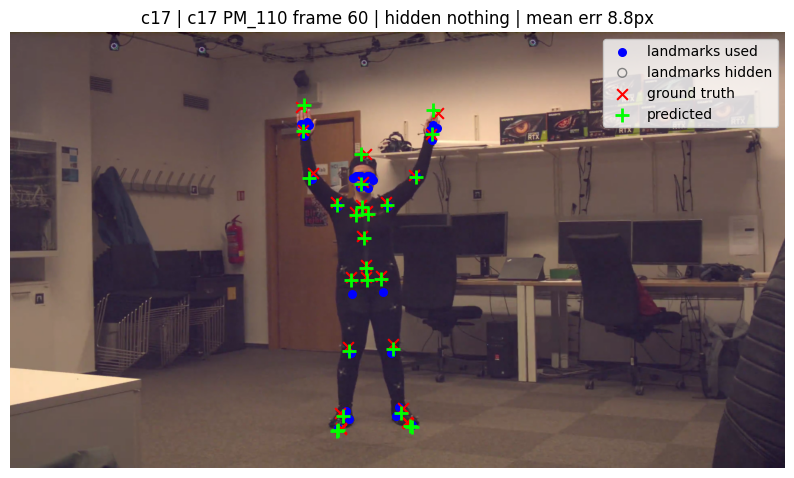

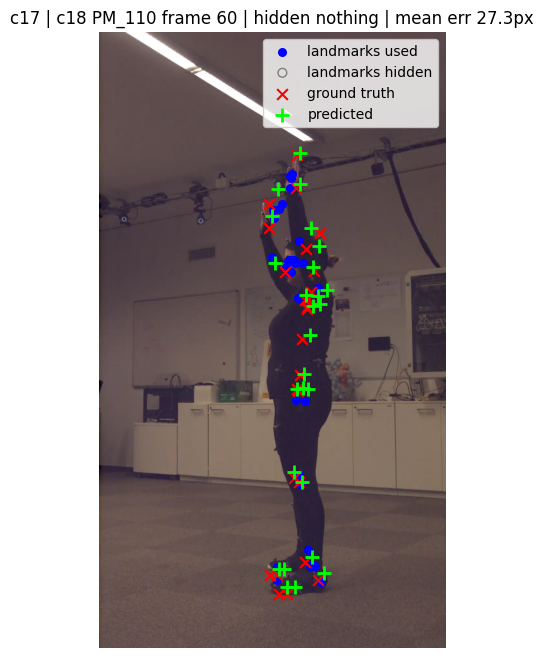

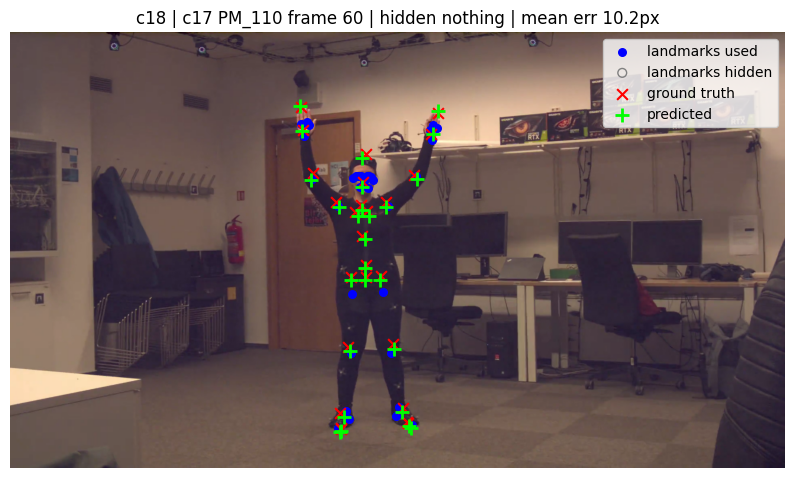

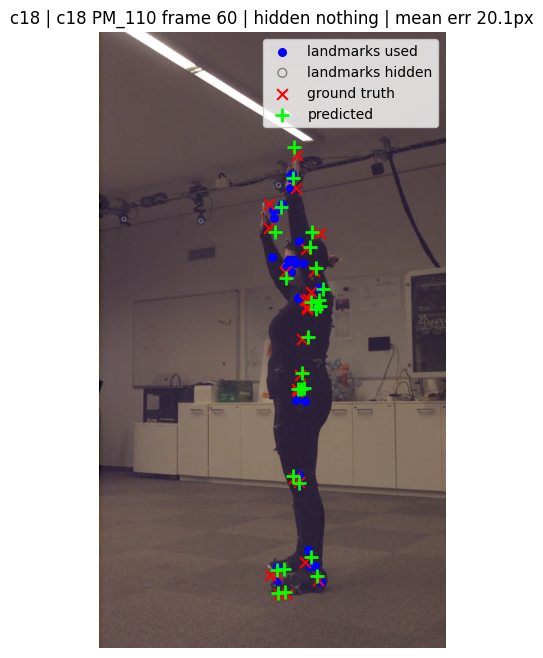

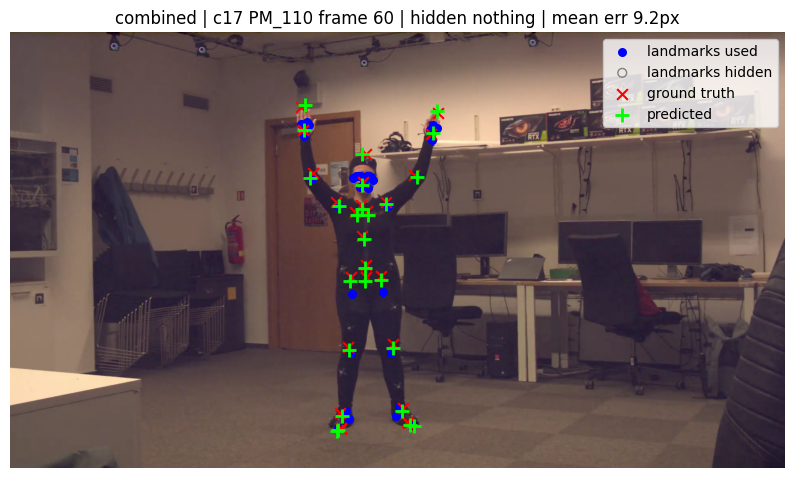

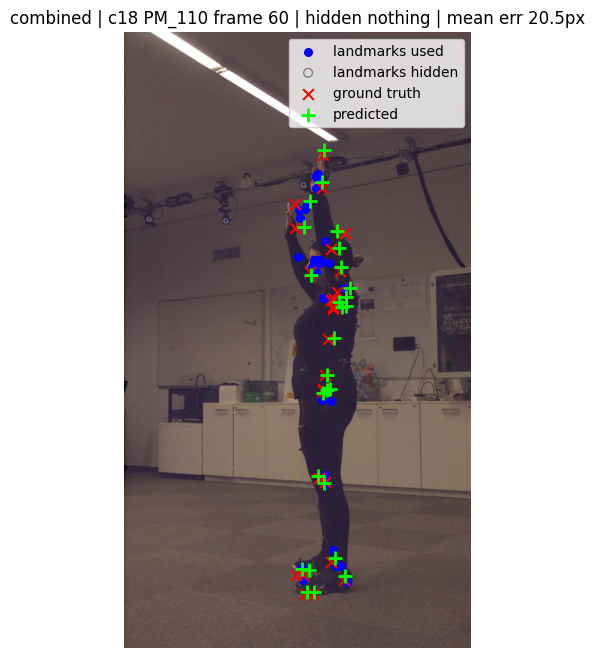

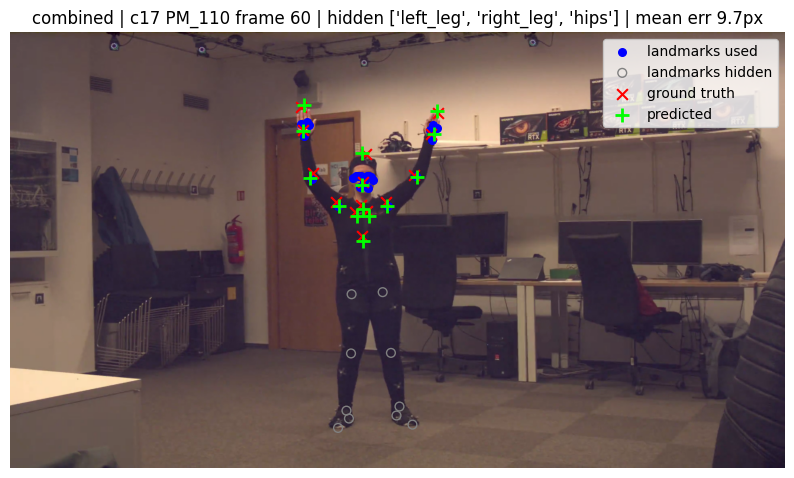

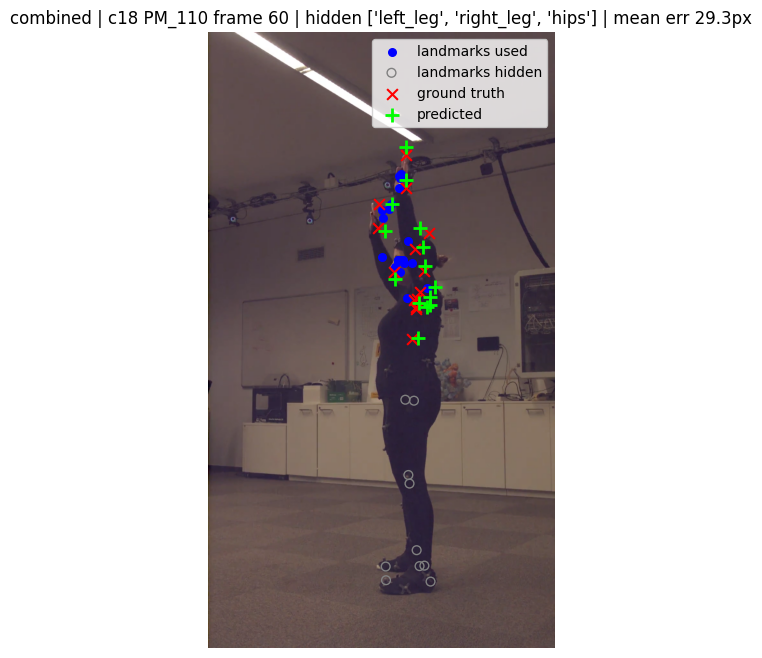

In [14]:
def predict_pixels(model, mp_frame, K, hidden_names=()):
    hidden = torch.zeros(1, G, dtype=torch.bool, device=DEVICE)
    for n in hidden_names:
        hidden[0, GROUP_NAMES.index(n)] = True
    lm_vis, joint_ok = masks_from_hidden(hidden)
    mp_t = torch.tensor(mp_frame, dtype=torch.float32, device=DEVICE)[None]
    c, s, _ = masked_anchor(mp_t, lm_vis, K["sh"], K["hp"])
    xn = (mp_t - c[:, None]) / s[:, None, None] * lm_vis[..., None]
    model.eval()
    with torch.no_grad():
        out = model(torch.cat([xn.flatten(1), lm_vis.float()], 1)).reshape(1, 26, 2)
    pred = (out * s[:, None, None] + c[:, None]).squeeze(0).cpu().numpy()
    return pred, joint_ok[0].cpu().numpy(), lm_vis[0].cpu().numpy()

def plot_overlay(model, K, view, subject, frame_idx=60, hidden_names=(), title=""):
    cands = [e for e in FILES if e["view"] == view and e["subject"] == subject]
    if not cands:
        print(f"no file for {subject} / {view}"); return
    e = cands[0]
    mp, gt, _ = load_pair(e)
    if frame_idx >= len(mp):
        print(f"frame {frame_idx} out of range ({len(mp)})"); return
    cap = cv2.VideoCapture(video_path(e)); cap.set(cv2.CAP_PROP_POS_FRAMES, frame_idx)
    ok_read, frame = cap.read(); cap.release()
    if not ok_read:
        print("could not read video frame"); return

    pred, ok, vis = predict_pixels(model, mp[frame_idx], K, hidden_names)
    err = np.linalg.norm(pred[ok] - gt[frame_idx][ok], axis=1).mean()
    plt.figure(figsize=(10, 8))
    plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    plt.scatter(*mp[frame_idx][vis].T, c="blue", s=30, label="landmarks used")
    plt.scatter(*mp[frame_idx][~vis].T, facecolors="none", edgecolors="gray", s=40, label="landmarks hidden")
    plt.scatter(*gt[frame_idx][ok].T, c="red", marker="x", s=60, label="ground truth")
    plt.scatter(*pred[ok].T, c="#00FF00", marker="+", s=90, linewidths=2, label="predicted")
    plt.title(f"{title} | {view} {subject} frame {frame_idx} | hidden {list(hidden_names) or 'nothing'} | mean err {err:.1f}px")
    plt.legend(loc="upper right"); plt.axis("off"); plt.show()

for name, model in MODELS.items():                                   # full body, every model and view
    for v in VIEWS:
        plot_overlay(model, INFO[name]["K"], v, SPLITS["test"][0], title=name)
for v in VIEWS:                                                      # lower body out of frame, combined model
    plot_overlay(MODELS["combined"], INFO["combined"]["K"], v, SPLITS["test"][0],
                 hidden_names=["left_leg", "right_leg", "hips"], title="combined")

In [ ]:
LM_GROUPS = {
    "head":      list(range(0, 11)),
    "shoulders": [11, 12],
    "hips":      [23, 24],
    "left_arm":  [13, 15, 17, 19, 21],
    "right_arm": [14, 16, 18, 20, 22],
    "left_leg":  [25, 27, 29, 31],
    "right_leg": [26, 28, 30, 32],
}

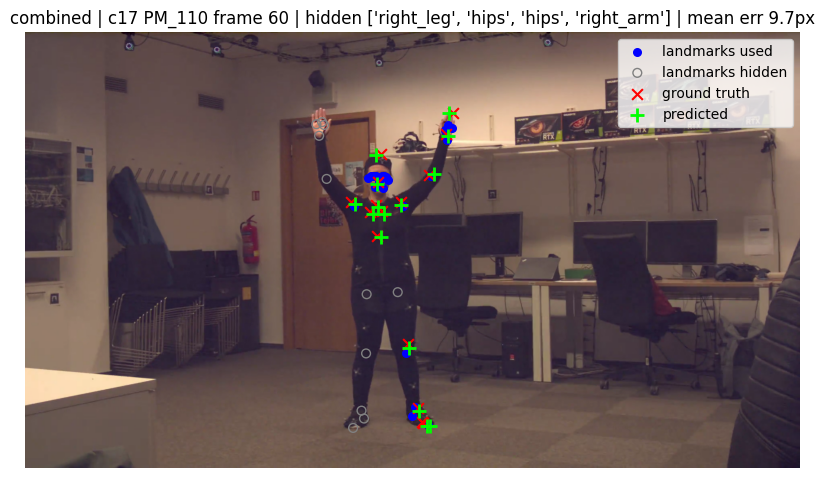

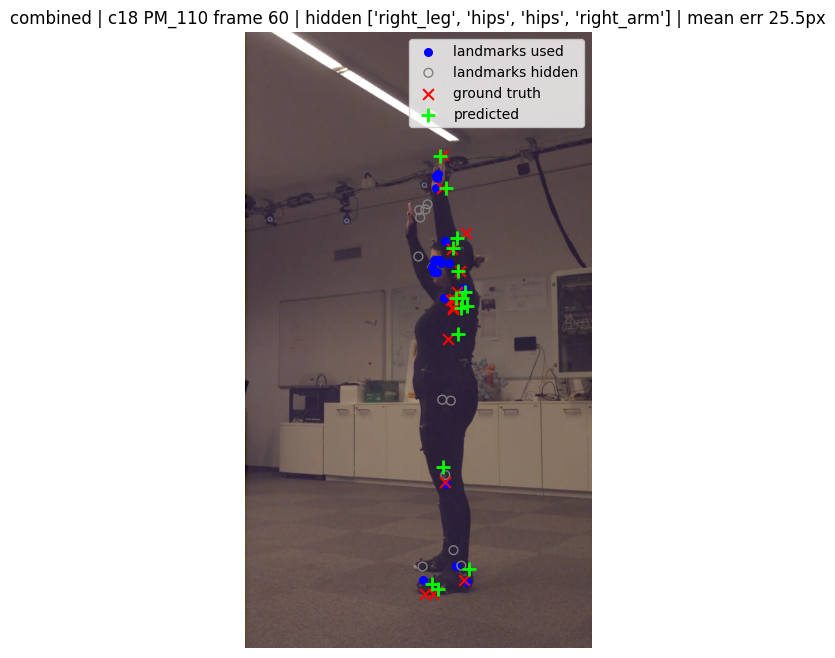

In [18]:
for v in VIEWS:                                                      # lower body out of frame, combined model
    plot_overlay(MODELS["combined"], INFO["combined"]["K"], v, SPLITS["test"][0],
                 hidden_names=["right_leg", "hips", "hips", "right_arm"], title="combined")